Trong xử lý ảnh, **histogram equalization** (cân bằng biểu đồ mức xám) là một kỹ thuật để cải thiện độ tương phản của ảnh. Công thức toán học để thực hiện cân bằng biểu đồ mức xám như sau:

1.  **Tính histogram của ảnh:** Histogram là một biểu đồ thể hiện tần suất xuất hiện của các mức xám trong ảnh. Giả sử ảnh có $L$ mức xám (thường là 256), histogram $h(g)$ là số lượng pixel có mức xám $g$.

2.  **Tính hàm phân phối tích lũy (CDF):**

    $CDF(g)= \sum_{i=0}^{g} h(i)$

    $CDF(g)$ là tổng số pixel có mức xám từ 0 đến $g$.

3.  **Chuẩn hóa CDF:**

    $CDF_{norm}(g)= \frac{CDF(g)-CDF_{min}}{(M \times N)-CDF_{min}} \times (L-1)$

    Trong đó:

    *   $M \times N$ là tổng số pixel trong ảnh.
    *   $CDF_{min}$ là giá trị nhỏ nhất của CDF (không tính các mức xám có tần suất 0).
    *   $L$ là số mức xám (thường là 256).

4.  **Ánh xạ lại mức xám:**

    $g_{new} = CDF_{norm}(g)$

    Mỗi mức xám $g$ trong ảnh gốc sẽ được thay thế bằng $g_{new}$

<ipython-input-42-c34eb2b61afd>:25: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])


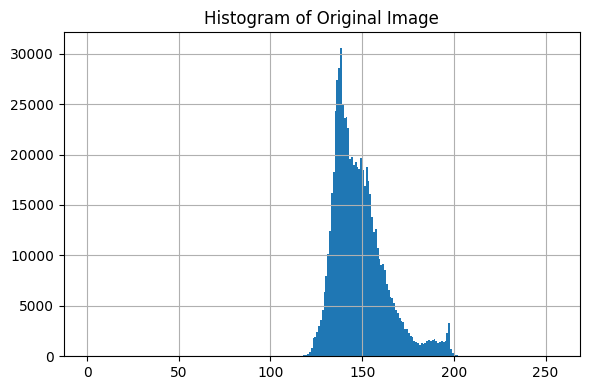

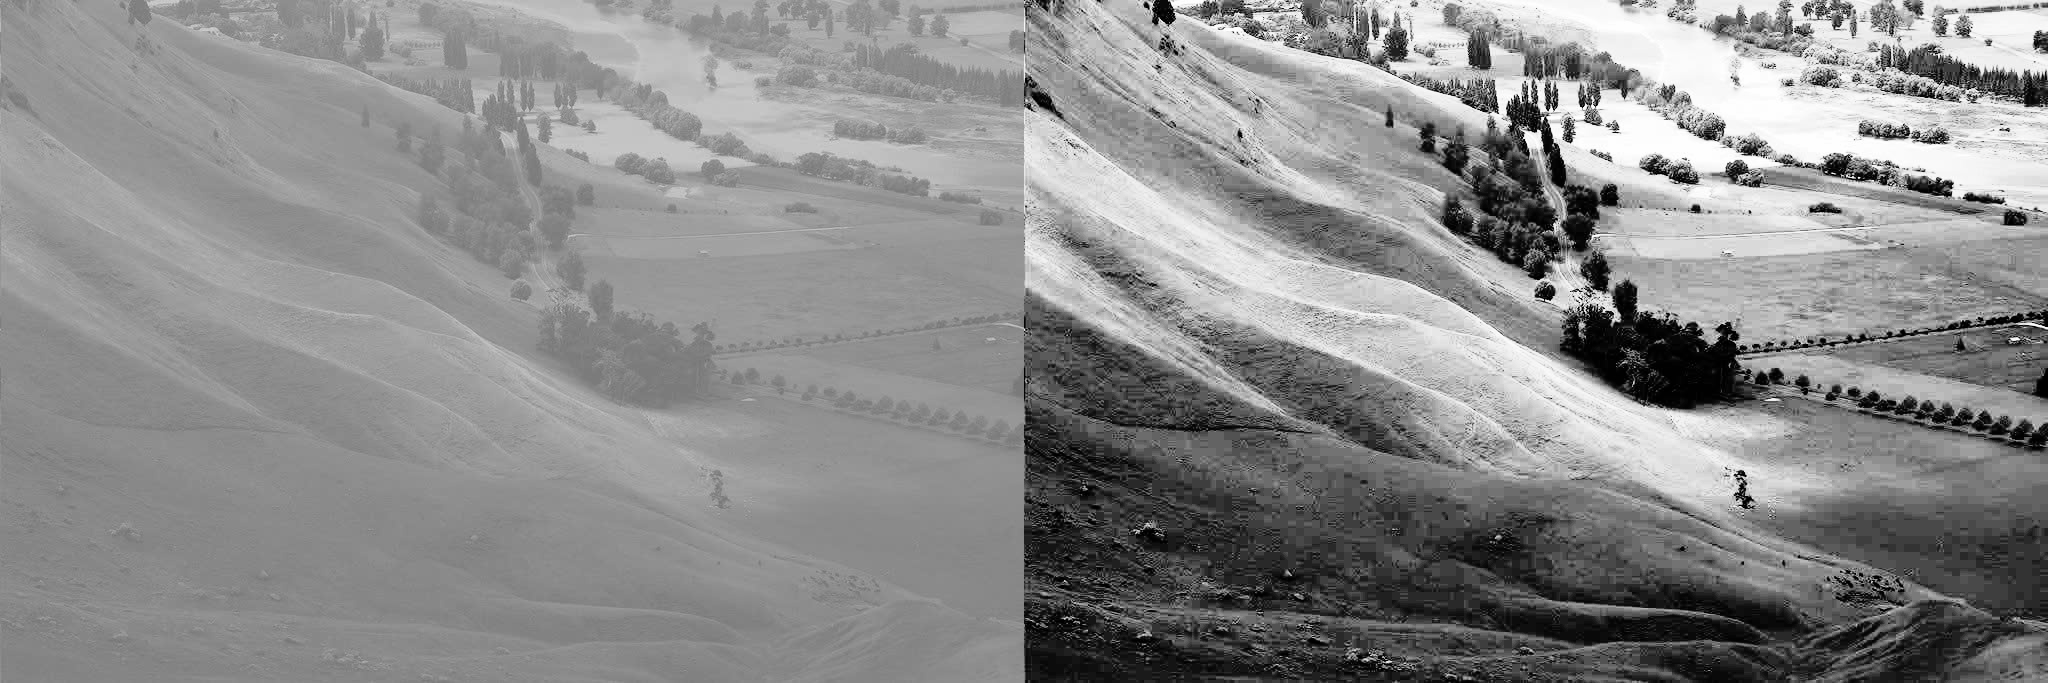

<ipython-input-42-c34eb2b61afd>:43: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equalized_img.ravel(), 256, [0, 256])


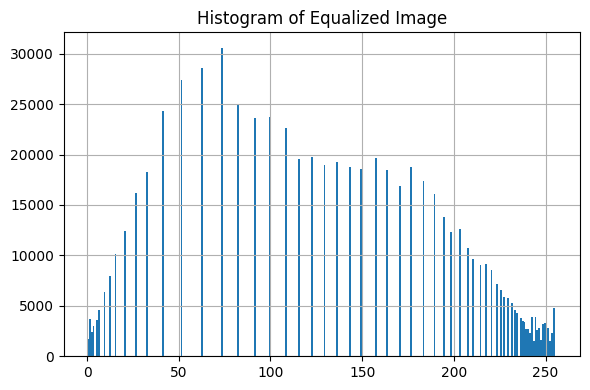

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab.patches import cv2_imshow


def histogram_equalization_manual(channel):
    hist, _ = np.histogram(channel.flatten(), bins=256, range=[0,256])
    cdf = hist.cumsum()
    cdf_masked = np.ma.masked_equal(cdf, 0)

    cdf_min = cdf_masked.min()
    cdf_max = cdf_masked.max()
    cdf_scaled = (cdf_masked - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_final = np.ma.filled(cdf_scaled, 0).astype('uint8')

    equalized = cdf_final[channel]
    return equalized

# Đọc ảnh
img = cv2.imread('/content/Unequalized_pic.jpg', 0)

# Hiển thị histogram của ảnh gốc
plt.figure(figsize=(6, 4))
plt.hist(img.ravel(), 256, [0, 256])
plt.title("Histogram of Original Image")

plt.grid()
plt.tight_layout()
plt.show()

# Cân bằng histogram
equalized_img = histogram_equalization_manual(img)

# Ghép ảnh gốc và ảnh đã cân bằng histogram
combine = np.hstack((img, equalized_img))

# Hiển thị ảnh đã cân bằng histogram
cv2_imshow(combine)

# Hiển thị histogram của ảnh đã cân bằng
plt.figure(figsize=(6, 4))
plt.hist(equalized_img.ravel(), 256, [0, 256])
plt.title("Histogram of Equalized Image")
plt.grid()
plt.tight_layout()
plt.show()


## Bài tập 1: Áp dụng cân bằng histogram cho ảnh màu:



- Chuyển đổi ảnh màu sang không gian màu HSV (Hue, Saturation, Value).

- Áp dụng cân bằng histogram chỉ trên kênh Value (V) để giữ nguyên màu sắc và độ bão hòa.

- Chuyển đổi ảnh trở lại không gian màu RGB và hiển thị kết quả.


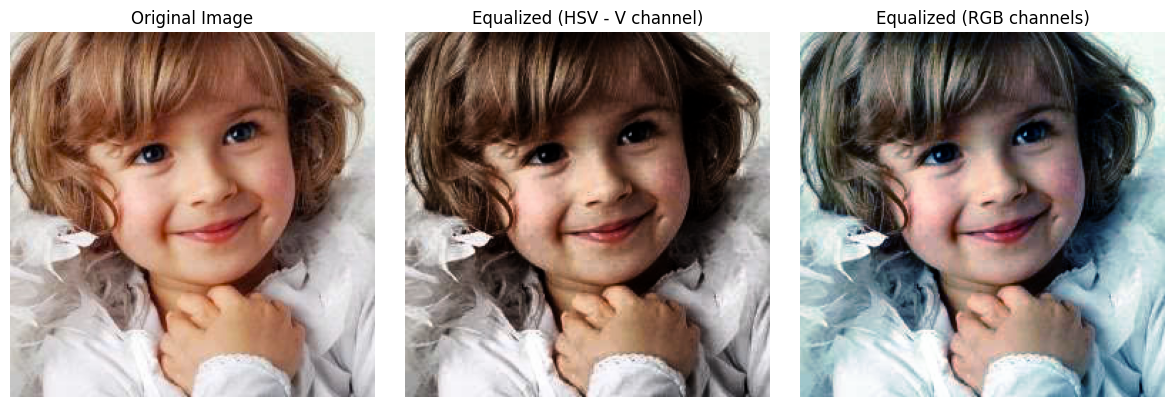

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread('/content/begai.jpg')

def histogram_equalization(channel):
    hist, _ = np.histogram(channel.flatten(), bins=256, range=[0,256])
    cdf = hist.cumsum()
    cdf_masked = np.ma.masked_equal(cdf, 0)

    cdf_min = cdf_masked.min()
    cdf_max = cdf_masked.max()
    cdf_scaled = (cdf_masked - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_final = np.ma.filled(cdf_scaled, 0).astype('uint8')

    equalized = cdf_final[channel]
    return equalized

# Chuyển đổi ảnh sang không gian màu HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

# Cân bằng histogram trên kênh Value (V)
v_cb = histogram_equalization(v)
hsv_cb = cv2.merge([h, s, v_cb])
img_hsv_cb = cv2.cvtColor(hsv_cb, cv2.COLOR_HSV2BGR)

# Chuyển đổi ảnh trở lại không gian màu RGB
b, g, r = cv2.split(img)
# Cân bằng histogram trực tiếp trên từng kênh màu R, G, B
r_cb = histogram_equalization(r)
g_cb = histogram_equalization(g)
b_cb = histogram_equalization(b)

img_rgb_cb = cv2.merge([b_cb, g_cb, r_cb])

# Hiển thị kết quả
plt.figure(figsize=(12, 4))


plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')


plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_hsv_cb, cv2.COLOR_BGR2RGB))
plt.title('Equalized (HSV - V channel)')
plt.axis('off')


plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_rgb_cb, cv2.COLOR_BGR2RGB))
plt.title('Equalized (RGB channels)')
plt.axis('off')

plt.tight_layout()
plt.show()


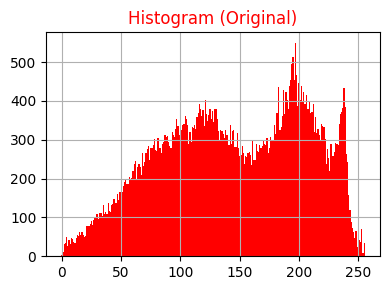

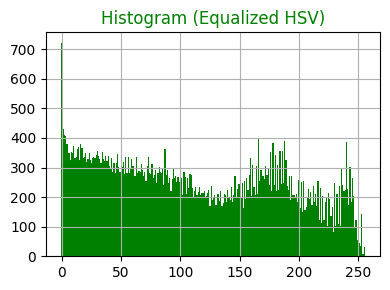

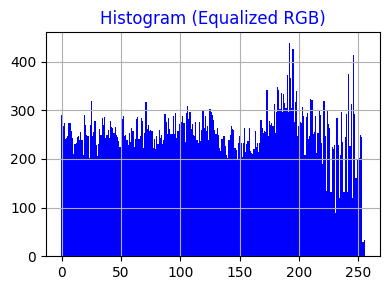

In [ ]:
# Tính và hiển thị histogram cho ảnh gốc
def bgr_to_gray(img_bgr):
    b, g, r = img_bgr[:,:,0], img_bgr[:,:,1], img_bgr[:,:,2]
    gray = (0.114 * b + 0.587 * g + 0.299 * r).astype(np.uint8)
    return gray

    # Tính và hiển thị histogram cho ảnh đã cân bằng HSV
    # Tính và hiển thị histogram cho ảnh đã cân bằng RGB
def plot_histogram(img_bgr, title):
    if 'Original' in title:
        color = 'red'
    elif 'HSV' in title:
        color = 'green'
    elif 'RGB' in title:
        color = 'blue'
    else:
        color = 'black'


    gray = bgr_to_gray(img_bgr)
    hist, _ = np.histogram(gray, bins=256, range=(0, 256))

    plt.figure(figsize=(4, 3))
    plt.bar(range(256), hist, color=color, width=1)
    plt.title(title, color=color)
    plt.tight_layout()
    plt.grid()
plot_histogram(img,'Histogram (Original)')
plot_histogram(img_hsv_cb,'Histogram (Equalized HSV)')
plot_histogram(img_rgb_cb,'Histogram (Equalized RGB)')

plt.show()

## Bài tập 1: Cân bằng histogram cục bộ (CLAHE)

Cân bằng histogram cục bộ (**CLAHE** - Contrast Limited Adaptive Histogram Equalization) là một biến thể của cân bằng histogram, trong đó ảnh được chia thành các vùng nhỏ (tiles) và cân bằng histogram được áp dụng riêng cho từng vùng. Điều này giúp tránh hiện tượng quá tăng cường độ tương phản ở các vùng đồng nhất.

1.  **Chia ảnh thành các tiles nhỏ:**

    Ảnh được chia thành các vùng nhỏ có kích thước $M \times N$.

2.  **Áp dụng cân bằng histogram cho từng tile:**

    Với mỗi tile, tính histogram và áp dụng cân bằng histogram như bình thường:

  
  $CDF(g)= \sum_{i=0}^{g} h(i)$

  $CDF_{norm}(g)= \frac{CDF(g)-CDF_{min}}{(M \times N)-CDF_{min}} \times (L-1)$

  $g_{new} = CDF_{norm}(g)$

3.  **Giới hạn độ tương phản (Contrast Limiting):**

    Để tránh hiện tượng nhiễu, giá trị histogram của mỗi tile được giới hạn bằng một ngưỡng (clip limit). Các giá trị vượt quá ngưỡng được phân phối lại đều trên toàn bộ histogram.

4.  **Nội suy giữa các tiles:**

    Để tránh hiện tượng biên giữa các tiles, các pixel ở biên được nội suy từ các tiles lân cận.

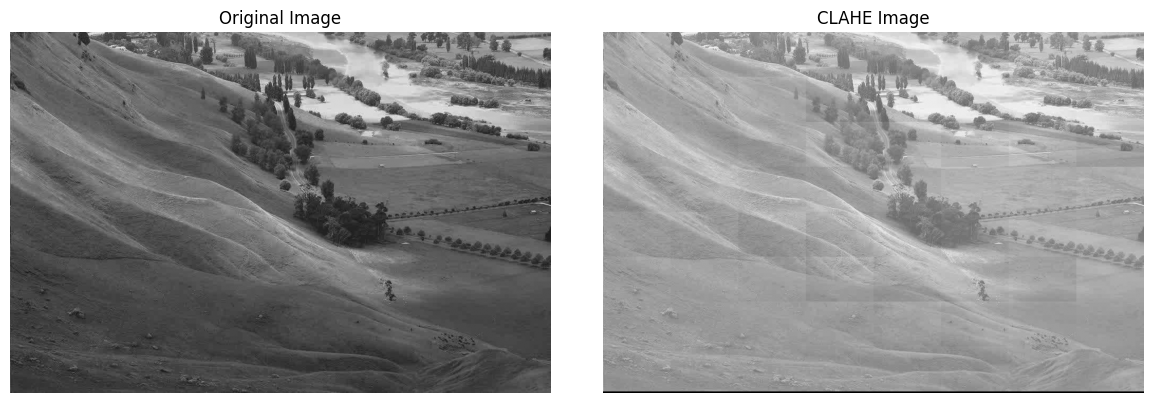

<ipython-input-50-4cb94291bc40>:62: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])
<ipython-input-50-4cb94291bc40>:66: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img_clahe.ravel(), 256, [0, 256])


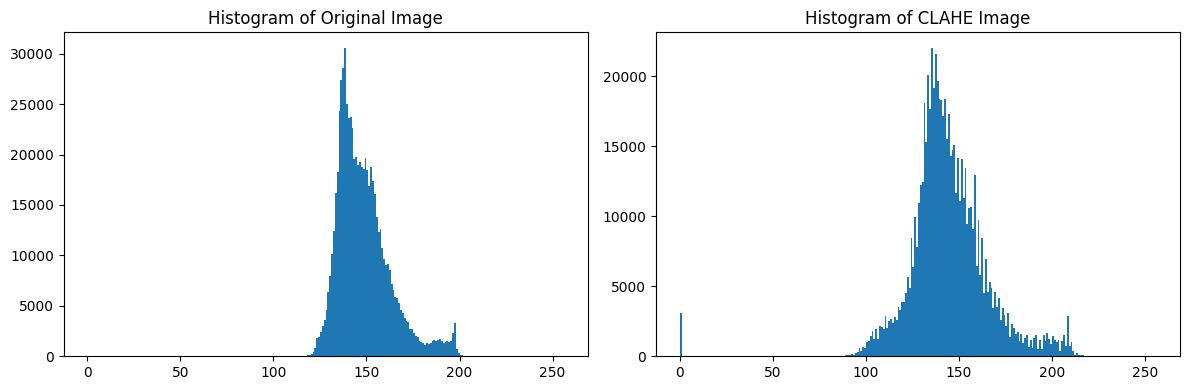

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Đọc ảnh

img = cv2.imread('/content/Unequalized_pic.jpg', 0)

# Áp dụng CLAHE
def equalize_hist(tile, clip_limit=40.0):
    hist, bins = np.histogram(tile.flatten(), 256, [0, 256])


    excess = hist - clip_limit
    excess[excess < 0] = 0
    total_excess = int(np.sum(excess))
    hist = np.clip(hist, 0, clip_limit)


    hist += total_excess // 256


    cdf = hist.cumsum()
    cdf_normalized = 255 * (cdf - cdf.min()) / (cdf.max() - cdf.min())
    cdf_normalized = cdf_normalized.astype(np.uint8)

    return cdf_normalized[tile]

def CLAHE(gray_img, tile_grid_size=(8, 8), clip_limit=40.0):
    h, w = gray_img.shape
    tile_h, tile_w = h // tile_grid_size[0], w // tile_grid_size[1]

    result = np.zeros_like(gray_img)

    for i in range(tile_grid_size[0]):
        for j in range(tile_grid_size[1]):
            y_start, y_end = i * tile_h, (i + 1) * tile_h
            x_start, x_end = j * tile_w, (j + 1) * tile_w

            tile = gray_img[y_start:y_end, x_start:x_end]
            equalized_tile =equalize_hist(tile, clip_limit)
            result[y_start:y_end, x_start:x_end] = equalized_tile

    return result
img_clahe = CLAHE(img, tile_grid_size=(8,8), clip_limit=40)
# Hiển thị ảnh gốc và ảnh đã xử lý
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(img_clahe, cmap='gray')
plt.title('CLAHE Image')
plt.axis('off')

plt.tight_layout()
plt.show()
# Hiển thị histogram
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(img.ravel(), 256, [0, 256])
plt.title('Histogram of Original Image')

plt.subplot(1,2,2)
plt.hist(img_clahe.ravel(), 256, [0, 256])
plt.title('Histogram of CLAHE Image')


plt.tight_layout()
plt.show()


##Bài tập 2: Cân bằng histogram trên các không gian màu khác (LAB, YCrCb)

Cân bằng histogram trên các không gian màu khác nhau sẽ cho kết quả khác nhau vì mỗi không gian màu biểu diễn ảnh theo các thành phần khác nhau.

### Không gian màu LAB:

- L (Lightness): Độ sáng.

- A, B: Thành phần màu.

- Cân bằng histogram trên kênh L để cải thiện độ tương phản mà không làm thay đổi màu sắc.

### Không gian màu YCrCb:

- Y (Luma): Độ sáng.

- Cr, Cb: Thành phần màu.

- Cân bằng histogram trên kênh Y để cải thiện độ tương phản.



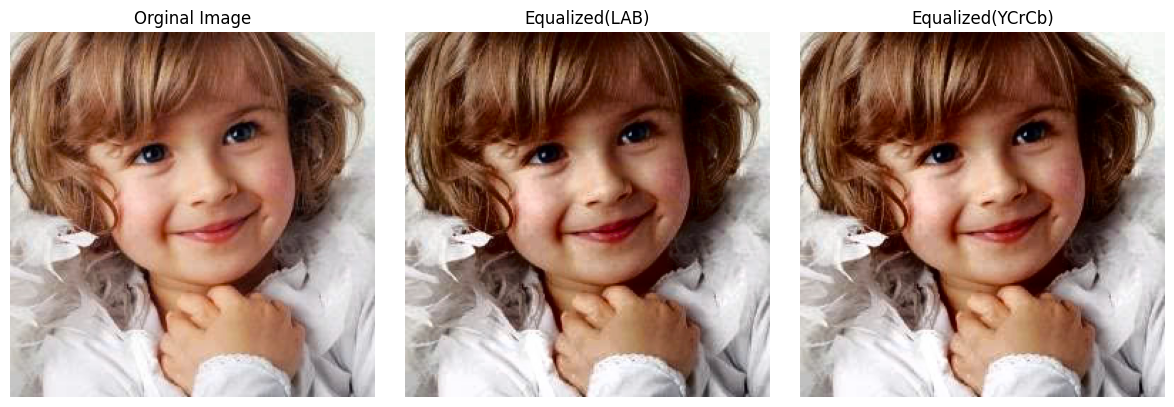

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt


img = cv2.imread('/content/begai.jpg')

# Chuyển đổi sang không gian màu LAB
img_rgb=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
# Cân bằng histogram trên kênh L
l_cb = cv2.equalizeHist(l)
lab_cb = cv2.merge([l_cb, a, b])
lab_cb_bgr = cv2.cvtColor(lab_cb, cv2.COLOR_LAB2BGR)
lab_cb_rgb = cv2.cvtColor(lab_cb_bgr, cv2.COLOR_BGR2RGB)

# Chuyển đổi sang không gian màu YCrCb
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
y, cr, cb = cv2.split(ycrcb)

# Cân bằng histogram trên kênh Y
y_cb = cv2.equalizeHist(y)
ycrcb_cb = cv2.merge([y_cb, cr, cb])
ycrcb_cb_bgr = cv2.cvtColor(ycrcb_cb, cv2.COLOR_YCrCb2BGR)
ycrcb_cb_rgb = cv2.cvtColor(ycrcb_cb_bgr, cv2.COLOR_BGR2RGB)

# Hiển thị kết quả
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img_rgb)
plt.title('Orginal Image')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(lab_cb_rgb)
plt.title('Equalized(LAB)')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(ycrcb_cb_rgb)
plt.title('Equalized(YCrCb)')
plt.axis('off')


plt.tight_layout()
plt.show()
